In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
import os

import pandas as pd
import matplotlib.pyplot as plt

from sqlalchemy import create_engine
from dotenv import load_dotenv
from pathlib import Path


PROJECT_ROOT = Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")


db_user = os.getenv("DB_USER")
db_password = os.getenv("DB_PASSWORD")
db_host = os.getenv("DB_HOST", "localhost")
db_port = os.getenv("DB_PORT", "5432")
db_name = os.getenv("DB_NAME")


if db_password:
    db_url = (
        f"postgresql+psycopg2://"
        f"{db_user}:{db_password}"
        f"@{db_host}:{db_port}/{db_name}"
    )
else:
    db_url = (
        f"postgresql+psycopg2://"
        f"{db_user}@{db_host}:{db_port}/{db_name}"
    )


engine = create_engine(db_url)

In [3]:
query = """
SELECT *
FROM dbt.mart_scm_risk_weekly
WHERE is_complete_week = true
ORDER BY week_end_date
"""

risk = pd.read_sql(query, engine)

risk["week_end_date"] = pd.to_datetime(
    risk["week_end_date"]
)

risk = (
    risk
    .sort_values("week_end_date")
    .reset_index(drop=True)
)

print(risk.shape)
print(
    risk["week_end_date"].min(),
    "~",
    risk["week_end_date"].max()
)

(156, 32)
2023-10-22 00:00:00 ~ 2026-10-11 00:00:00


In [4]:
risk["is_feature_reliable"] = (
    (risk["wholesale_qty_obs"] >= 3) &
    (risk["wholesale_price_obs"] >= 3) &
    (risk["retail_price_obs"] >= 3)
)

risk["is_wholesale_target_reliable"] = (
    risk["wholesale_price_obs"] >= 3
)

risk["next_target_reliable"] = (
    risk["is_wholesale_target_reliable"]
    .shift(-1)
    .fillna(False)
    .astype(bool)
)

/var/folders/9k/gfjrzlbs4m944f17wkmd4j600000gn/T/ipykernel_40093/2694447137.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [5]:
risk["avg_daily_qty"] = (
    risk["wholesale_qty"]
    / risk["wholesale_qty_obs"].replace(0, np.nan)
)

risk["qty_baseline_12w"] = (
    risk["avg_daily_qty"]
    .shift(1)
    .rolling(
        12,
        min_periods=6
    )
    .median()
)

risk["qty_index_12w"] = (
    risk["avg_daily_qty"]
    / risk["qty_baseline_12w"]
)

In [6]:
risk["price_baseline_12w"] = (
    risk["wholesale_price"]
    .shift(1)
    .rolling(
        12,
        min_periods=6
    )
    .median()
)

risk["price_index_12w"] = (
    risk["wholesale_price"]
    / risk["price_baseline_12w"]
)

In [7]:
risk["retail_baseline_12w"] = (
    risk["retail_price"]
    .shift(1)
    .rolling(
        12,
        min_periods=6
    )
    .median()
)

risk["retail_index_12w"] = (
    risk["retail_price"]
    / risk["retail_baseline_12w"]
)

In [8]:
risk["price_log_change_1w"] = (
    np.log(risk["wholesale_price"])
    .diff()
)

risk["qty_log_change_1w"] = (
    np.log1p(risk["avg_daily_qty"])
    .diff()
)

In [9]:
risk["week_of_year"] = (
    risk["week_end_date"]
    .dt.isocalendar()
    .week
    .astype(int)
)

risk["season_sin"] = np.sin(
    2 * np.pi
    * risk["week_of_year"]
    / 52
)

risk["season_cos"] = np.cos(
    2 * np.pi
    * risk["week_of_year"]
    / 52
)

In [10]:
weather_base_cols = [
    "mokpo_avg_temp_30d",
    "mokpo_humidity_30d",
    "mokpo_sunshine_30d",

    "jeju_avg_temp_30d",
    "jeju_humidity_30d",
    "jeju_sunshine_30d",

    "hapcheon_avg_temp_30d",
    "hapcheon_humidity_30d",
    "hapcheon_sunshine_30d",
]

for col in weather_base_cols:

    baseline_col = f"{col}_baseline_12w"
    deviation_col = f"{col}_dev_12w"

    risk[baseline_col] = (
        risk[col]
        .shift(1)
        .rolling(
            12,
            min_periods=6
        )
        .median()
    )

    risk[deviation_col] = (
        risk[col]
        - risk[baseline_col]
    )

In [11]:
market_features = [
    "price_index_12w",
    "qty_index_12w",
    "retail_index_12w",

    "price_log_change_1w",
    "qty_log_change_1w",

    "season_sin",
    "season_cos",
]

In [12]:
weather_features = [
    "mokpo_avg_temp_30d_dev_12w",
    "mokpo_humidity_30d_dev_12w",
    "mokpo_sunshine_30d_dev_12w",

    "jeju_avg_temp_30d_dev_12w",
    "jeju_humidity_30d_dev_12w",
    "jeju_sunshine_30d_dev_12w",

    "hapcheon_avg_temp_30d_dev_12w",
    "hapcheon_humidity_30d_dev_12w",
    "hapcheon_sunshine_30d_dev_12w",
]

In [13]:
market_weather_features = (
    market_features
    + weather_features
)

In [14]:
# ==================================================
# Target 생성
# 반드시 전체 연속 주차 risk에서 먼저 shift
# ==================================================

risk["next_price_index"] = (
    risk["price_index_12w"]
    .shift(-1)
)


# 다음 주 도매가격 Target 신뢰도
risk["next_target_reliable"] = (
    risk["is_wholesale_target_reliable"]
    .shift(-1)
    .fillna(False)
    .astype(bool)
)


# ==================================================
# Model Dataset 생성
# ==================================================

model_df = risk[
    risk["is_feature_reliable"]
    &
    risk["next_target_reliable"]
].copy()


# 모델에 필요한 모든 Feature + Target
required_cols = (
    market_weather_features
    + ["next_price_index"]
)


# Feature / Target 결측 제거
model_df = (
    model_df
    .dropna(subset=required_cols)
    .reset_index(drop=True)
)

/var/folders/9k/gfjrzlbs4m944f17wkmd4j600000gn/T/ipykernel_40093/812625726.py:16: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [15]:
print("Model rows:", len(model_df))

print(
    "Period:",
    model_df["week_end_date"].min(),
    "~",
    model_df["week_end_date"].max()
)

print(
    "next_price_index exists:",
    "next_price_index" in model_df.columns
)

print(
    "Missing values:",
    model_df[
        market_weather_features
        + ["next_price_index"]
    ]
    .isna()
    .sum()
    .sum()
)

Model rows: 115
Period: 2024-02-04 00:00:00 ~ 2026-10-04 00:00:00
next_price_index exists: True
Missing values: 0


In [16]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [17]:
def make_ridge_model(alpha=1.0):

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            Ridge(alpha=alpha)
        )
    ])

In [18]:
tscv = TimeSeriesSplit(
    n_splits=4,
    test_size=13
)

In [19]:
for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(model_df),
    start=1
):

    train = model_df.iloc[train_idx]
    valid = model_df.iloc[valid_idx]

    print(
        f"Fold {fold}"
    )

    print(
        "Train:",
        train["week_end_date"].min(),
        "~",
        train["week_end_date"].max(),
        f"({len(train)} rows)"
    )

    print(
        "Valid:",
        valid["week_end_date"].min(),
        "~",
        valid["week_end_date"].max(),
        f"({len(valid)} rows)"
    )

    print("-" * 60)

Fold 1
Train: 2024-02-04 00:00:00 ~ 2025-09-21 00:00:00 (63 rows)
Valid: 2025-09-28 00:00:00 ~ 2025-12-28 00:00:00 (13 rows)
------------------------------------------------------------
Fold 2
Train: 2024-02-04 00:00:00 ~ 2025-12-28 00:00:00 (76 rows)
Valid: 2026-01-04 00:00:00 ~ 2026-04-05 00:00:00 (13 rows)
------------------------------------------------------------
Fold 3
Train: 2024-02-04 00:00:00 ~ 2026-04-05 00:00:00 (89 rows)
Valid: 2026-04-12 00:00:00 ~ 2026-07-05 00:00:00 (13 rows)
------------------------------------------------------------
Fold 4
Train: 2024-02-04 00:00:00 ~ 2026-07-05 00:00:00 (102 rows)
Valid: 2026-07-12 00:00:00 ~ 2026-10-04 00:00:00 (13 rows)
------------------------------------------------------------


In [20]:
results = []
predictions = []


for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(model_df),
    start=1
):

    train = model_df.iloc[train_idx].copy()
    valid = model_df.iloc[valid_idx].copy()

    y_train = train["next_price_index"]
    y_valid = valid["next_price_index"]


    # ==================================================
    # 1. Naive Baseline
    # 현재 price risk가 다음 주에도 유지된다고 가정
    # ==================================================

    naive_pred = (
        valid["price_index_12w"]
        .to_numpy()
    )


    # ==================================================
    # 2. Market-only Model
    # ==================================================

    market_model = make_ridge_model(
        alpha=1.0
    )

    market_model.fit(
        train[market_features],
        y_train
    )

    market_pred = market_model.predict(
        valid[market_features]
    )


    # ==================================================
    # 3. Market + Weather Model
    # ==================================================

    market_weather_model = make_ridge_model(
        alpha=1.0
    )

    market_weather_model.fit(
        train[market_weather_features],
        y_train
    )

    market_weather_pred = (
        market_weather_model.predict(
            valid[market_weather_features]
        )
    )


    # ==================================================
    # 성능 저장
    # ==================================================

    fold_predictions = {
        "Naive": naive_pred,
        "Market": market_pred,
        "Market + Weather": market_weather_pred
    }

    for model_name, pred in fold_predictions.items():

        mae = mean_absolute_error(
            y_valid,
            pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_valid,
                pred
            )
        )

        results.append({
            "fold": fold,
            "model": model_name,

            "train_start":
                train["week_end_date"].min(),

            "train_end":
                train["week_end_date"].max(),

            "valid_start":
                valid["week_end_date"].min(),

            "valid_end":
                valid["week_end_date"].max(),

            "n_train":
                len(train),

            "n_valid":
                len(valid),

            "mae":
                mae,

            "rmse":
                rmse
        })


    # ==================================================
    # 시계열 Prediction 저장
    # ==================================================

    for i in range(len(valid)):

        predictions.append({

            "week_end_date":
                valid.iloc[i]["week_end_date"],

            "actual":
                y_valid.iloc[i],

            "naive":
                naive_pred[i],

            "market":
                market_pred[i],

            "market_weather":
                market_weather_pred[i],

            "fold":
                fold
        })

In [21]:
fold_results = pd.DataFrame(
    results
)

fold_results

,fold,model,train_start,train_end,valid_start,valid_end,n_train,n_valid,mae,rmse
0,1,Naive,2024-02-04,2025-09-21,2025-09-28,2025-12-28,63,13,0.122801,0.137543
1,1,Market,2024-02-04,2025-09-21,2025-09-28,2025-12-28,63,13,0.087761,0.105141
2,1,Market + Weather,2024-02-04,2025-09-21,2025-09-28,2025-12-28,63,13,0.117186,0.148588
3,2,Naive,2024-02-04,2025-12-28,2026-01-04,2026-04-05,76,13,0.072608,0.092442
4,2,Market,2024-02-04,2025-12-28,2026-01-04,2026-04-05,76,13,0.064782,0.077258
5,2,Market + Weather,2024-02-04,2025-12-28,2026-01-04,2026-04-05,76,13,0.068777,0.081421
6,3,Naive,2024-02-04,2026-04-05,2026-04-12,2026-07-05,89,13,0.108623,0.132197
7,3,Market,2024-02-04,2026-04-05,2026-04-12,2026-07-05,89,13,0.090577,0.102498
8,3,Market + Weather,2024-02-04,2026-04-05,2026-04-12,2026-07-05,89,13,0.102723,0.121825
9,4,Naive,2024-02-04,2026-07-05,2026-07-12,2026-10-04,102,13,0.093274,0.104614


In [22]:
fold_results[
    [
        "fold",
        "model",
        "train_start",
        "train_end",
        "valid_start",
        "valid_end",
        "n_train",
        "n_valid",
        "mae",
        "rmse"
    ]
]

,fold,model,train_start,train_end,valid_start,valid_end,n_train,n_valid,mae,rmse
0,1,Naive,2024-02-04,2025-09-21,2025-09-28,2025-12-28,63,13,0.122801,0.137543
1,1,Market,2024-02-04,2025-09-21,2025-09-28,2025-12-28,63,13,0.087761,0.105141
2,1,Market + Weather,2024-02-04,2025-09-21,2025-09-28,2025-12-28,63,13,0.117186,0.148588
3,2,Naive,2024-02-04,2025-12-28,2026-01-04,2026-04-05,76,13,0.072608,0.092442
4,2,Market,2024-02-04,2025-12-28,2026-01-04,2026-04-05,76,13,0.064782,0.077258
5,2,Market + Weather,2024-02-04,2025-12-28,2026-01-04,2026-04-05,76,13,0.068777,0.081421
6,3,Naive,2024-02-04,2026-04-05,2026-04-12,2026-07-05,89,13,0.108623,0.132197
7,3,Market,2024-02-04,2026-04-05,2026-04-12,2026-07-05,89,13,0.090577,0.102498
8,3,Market + Weather,2024-02-04,2026-04-05,2026-04-12,2026-07-05,89,13,0.102723,0.121825
9,4,Naive,2024-02-04,2026-07-05,2026-07-12,2026-10-04,102,13,0.093274,0.104614


In [23]:
model_summary = (
    fold_results
    .groupby("model")
    .agg(
        mean_mae=("mae", "mean"),
        std_mae=("mae", "std"),

        mean_rmse=("rmse", "mean"),
        std_rmse=("rmse", "std")
    )
    .sort_values("mean_mae")
)

model_summary

,mean_mae,std_mae,mean_rmse,std_rmse
model,,,,
Market,0.080956,0.011554,0.094428,0.012614
Market + Weather,0.089908,0.023905,0.108147,0.033102
Naive,0.099327,0.021509,0.116699,0.021672


In [24]:
# ==================================================
# 전체 평균 성능 기준 개선율
# ==================================================

naive_mae = (
    model_summary
    .loc[
        "Naive",
        "mean_mae"
    ]
)

market_mae = (
    model_summary
    .loc[
        "Market",
        "mean_mae"
    ]
)

weather_mae = (
    model_summary
    .loc[
        "Market + Weather",
        "mean_mae"
    ]
)


# Market이 Naive 대비 얼마나 개선되었는가
market_vs_naive_pct = (
    (naive_mae - market_mae)
    / naive_mae
    * 100
)


# Weather 추가가 Market 대비 얼마나 개선되었는가
weather_vs_market_pct = (
    (market_mae - weather_mae)
    / market_mae
    * 100
)


print(
    f"Naive MAE: "
    f"{naive_mae:.4f}"
)

print(
    f"Market MAE: "
    f"{market_mae:.4f}"
)

print(
    f"Market + Weather MAE: "
    f"{weather_mae:.4f}"
)

print()

print(
    f"Market vs Naive improvement: "
    f"{market_vs_naive_pct:.2f}%"
)

print(
    f"Weather vs Market improvement: "
    f"{weather_vs_market_pct:.2f}%"
)

Naive MAE: 0.0993
Market MAE: 0.0810
Market + Weather MAE: 0.0899

Market vs Naive improvement: 18.50%
Weather vs Market improvement: -11.06%


In [25]:
fold_compare = (
    fold_results
    .pivot(
        index="fold",
        columns="model",
        values="mae"
    )
    .reset_index()
)


# --------------------------------------------------
# Market vs Naive
# 양수 = Market이 더 좋음
# --------------------------------------------------

fold_compare["market_vs_naive_pct"] = (
    (
        fold_compare["Naive"]
        -
        fold_compare["Market"]
    )
    /
    fold_compare["Naive"]
    *
    100
)


# --------------------------------------------------
# Weather vs Market
# 양수 = Weather 추가가 더 좋음
# --------------------------------------------------

fold_compare["weather_vs_market_pct"] = (
    (
        fold_compare["Market"]
        -
        fold_compare["Market + Weather"]
    )
    /
    fold_compare["Market"]
    *
    100
)


fold_compare

model,fold,Market,Market + Weather,Naive,market_vs_naive_pct,weather_vs_market_pct
0,1,0.087761,0.117186,0.122801,28.534008,-33.528807
1,2,0.064782,0.068777,0.072608,10.778624,-6.165814
2,3,0.090577,0.102723,0.108623,16.614032,-13.409506
3,4,0.080704,0.070947,0.093274,13.476774,12.089431


In [26]:
pred_df = (
    pd.DataFrame(predictions)
    .sort_values("week_end_date")
    .reset_index(drop=True)
)

pred_df.head()

,week_end_date,actual,naive,market,market_weather,fold
0,2025-09-28,1.017088,0.920740,1.000800,1.057356,1
1,2025-10-05,1.068100,1.017088,0.998852,1.068873,1
2,2025-10-19,1.095280,1.100832,1.085038,1.135838,1
3,2025-10-26,0.956726,1.095280,1.117418,1.128944,1
4,2025-11-02,1.156110,0.956726,1.053146,1.057619,1


In [27]:
pred_df.tail()

,week_end_date,actual,naive,market,market_weather,fold
47,2026-09-06,1.231528,1.182188,1.156312,1.160792,4
48,2026-09-13,1.040231,1.231528,1.161390,1.134677,4
49,2026-09-20,1.175733,1.040231,1.102753,1.077725,4
50,2026-09-27,1.138085,1.175733,1.100639,1.079213,4
51,2026-10-04,1.040716,1.138085,1.132292,1.097717,4


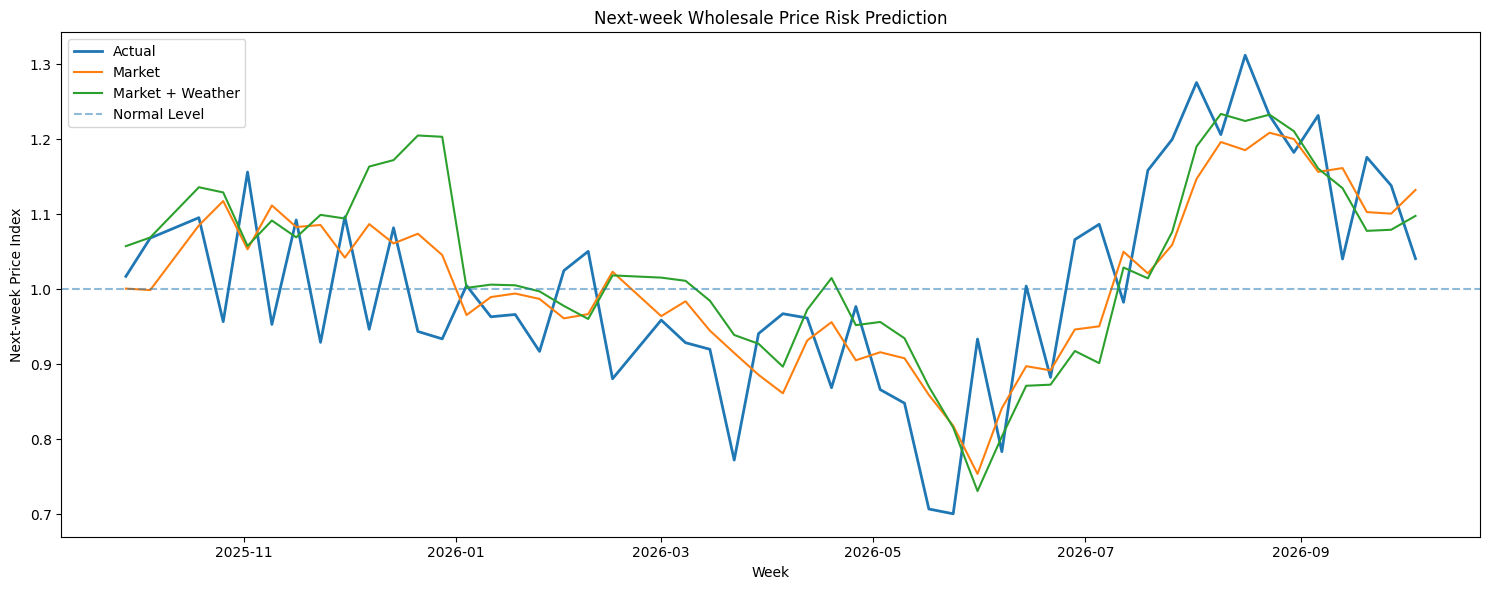

In [28]:
plt.figure(
    figsize=(15, 6)
)

plt.plot(
    pred_df["week_end_date"],
    pred_df["actual"],
    label="Actual",
    linewidth=2
)

plt.plot(
    pred_df["week_end_date"],
    pred_df["market"],
    label="Market"
)

plt.plot(
    pred_df["week_end_date"],
    pred_df["market_weather"],
    label="Market + Weather"
)

plt.axhline(
    1.0,
    linestyle="--",
    alpha=0.5,
    label="Normal Level"
)

plt.title(
    "Next-week Wholesale Price Risk Prediction"
)

plt.xlabel(
    "Week"
)

plt.ylabel(
    "Next-week Price Index"
)

plt.legend()

plt.tight_layout()

plt.show()

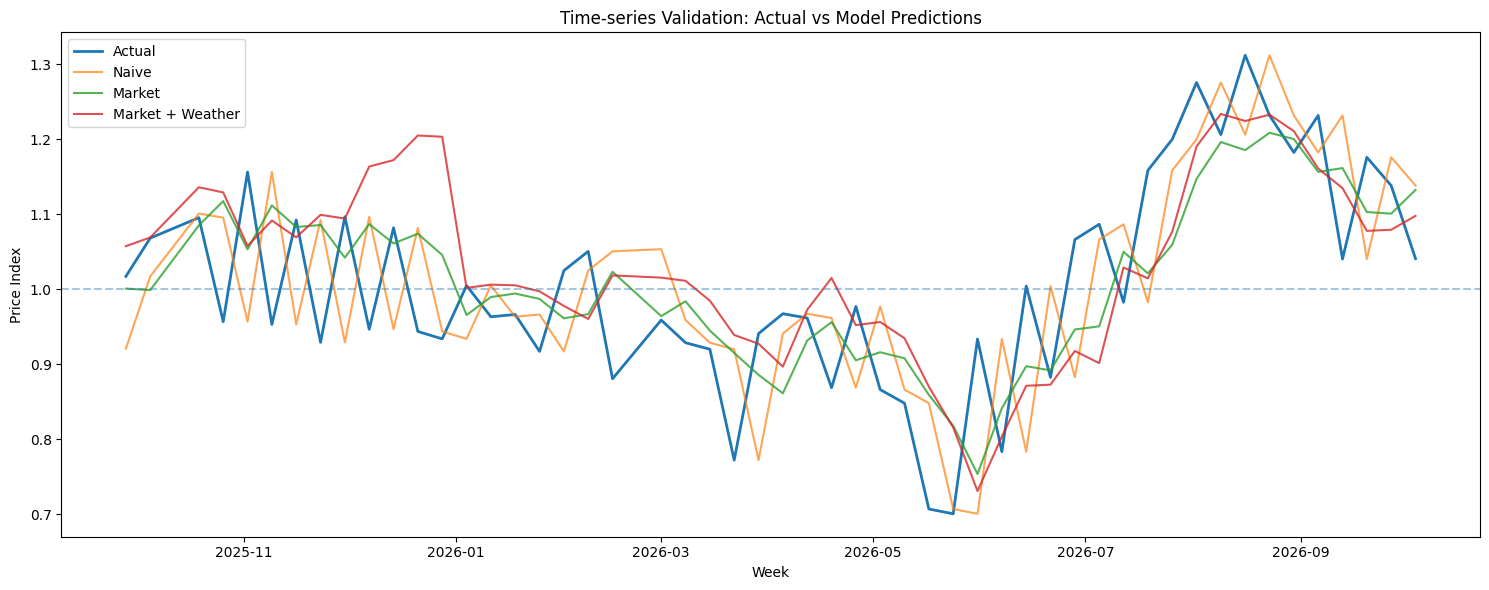

In [29]:
plt.figure(
    figsize=(15, 6)
)

plt.plot(
    pred_df["week_end_date"],
    pred_df["actual"],
    label="Actual",
    linewidth=2
)

plt.plot(
    pred_df["week_end_date"],
    pred_df["naive"],
    label="Naive",
    alpha=0.7
)

plt.plot(
    pred_df["week_end_date"],
    pred_df["market"],
    label="Market",
    alpha=0.8
)

plt.plot(
    pred_df["week_end_date"],
    pred_df["market_weather"],
    label="Market + Weather",
    alpha=0.8
)

plt.axhline(
    1.0,
    linestyle="--",
    alpha=0.4
)

plt.title(
    "Time-series Validation: "
    "Actual vs Model Predictions"
)

plt.xlabel("Week")
plt.ylabel("Price Index")

plt.legend()

plt.tight_layout()

plt.show()

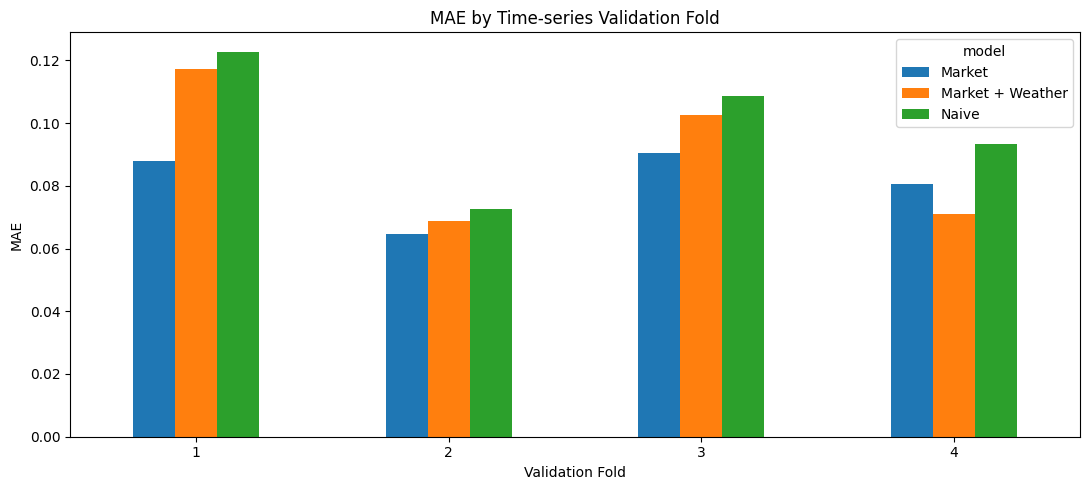

In [30]:
mae_pivot = (
    fold_results
    .pivot(
        index="fold",
        columns="model",
        values="mae"
    )
)

mae_pivot.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title(
    "MAE by Time-series Validation Fold"
)

plt.xlabel(
    "Validation Fold"
)

plt.ylabel(
    "MAE"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()

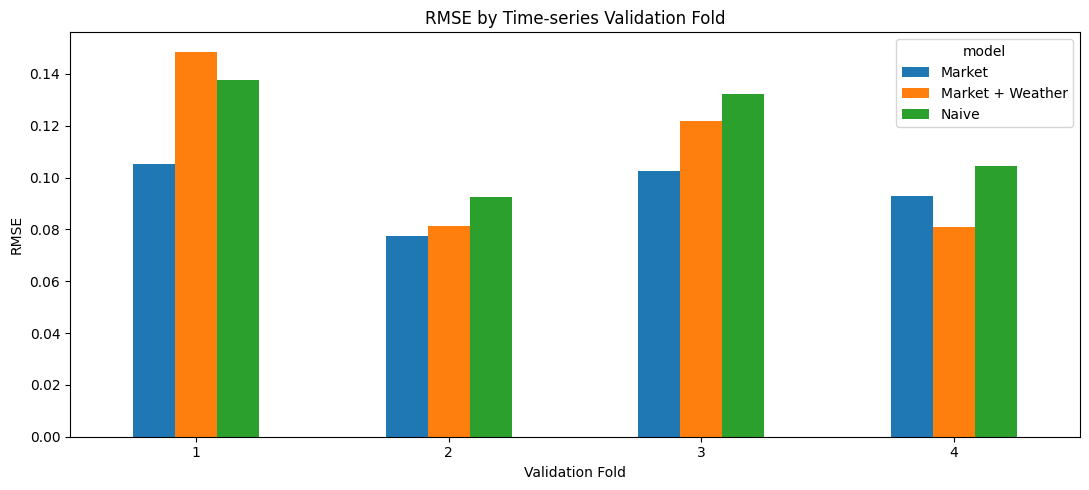

In [31]:
rmse_pivot = (
    fold_results
    .pivot(
        index="fold",
        columns="model",
        values="rmse"
    )
)

rmse_pivot.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title(
    "RMSE by Time-series Validation Fold"
)

plt.xlabel(
    "Validation Fold"
)

plt.ylabel(
    "RMSE"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()

In [32]:
print(
    "=" * 60
)

print(
    "MODEL DATA"
)

print(
    "=" * 60
)

print(
    "Rows:",
    len(model_df)
)

print(
    "Period:",
    model_df["week_end_date"].min(),
    "~",
    model_df["week_end_date"].max()
)


print(
    "\n" + "=" * 60
)

print(
    "MODEL SUMMARY"
)

print(
    "=" * 60
)

display(
    model_summary
)


print(
    "\n" + "=" * 60
)

print(
    "FOLD COMPARISON"
)

print(
    "=" * 60
)

display(
    fold_compare
)


print(
    "\n" + "=" * 60
)

print(
    "INCREMENTAL VALUE"
)

print(
    "=" * 60
)

print(
    f"Market vs Naive: "
    f"{market_vs_naive_pct:.2f}%"
)

print(
    f"Weather vs Market: "
    f"{weather_vs_market_pct:.2f}%"
)

MODEL DATA
Rows: 115
Period: 2024-02-04 00:00:00 ~ 2026-10-04 00:00:00

MODEL SUMMARY


,mean_mae,std_mae,mean_rmse,std_rmse
model,,,,
Market,0.080956,0.011554,0.094428,0.012614
Market + Weather,0.089908,0.023905,0.108147,0.033102
Naive,0.099327,0.021509,0.116699,0.021672



FOLD COMPARISON


model,fold,Market,Market + Weather,Naive,market_vs_naive_pct,weather_vs_market_pct
0,1,0.087761,0.117186,0.122801,28.534008,-33.528807
1,2,0.064782,0.068777,0.072608,10.778624,-6.165814
2,3,0.090577,0.102723,0.108623,16.614032,-13.409506
3,4,0.080704,0.070947,0.093274,13.476774,12.089431



INCREMENTAL VALUE
Market vs Naive: 18.50%
Weather vs Market: -11.06%


In [33]:
final_market_model = make_ridge_model(
    alpha=1.0
)

final_market_model.fit(
    model_df[market_features],
    model_df["next_price_index"]
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None


In [34]:
market_coef = pd.DataFrame({
    "feature": market_features,
    "coefficient": (
        final_market_model
        .named_steps["model"]
        .coef_
    )
})

market_coef["abs_coefficient"] = (
    market_coef["coefficient"]
    .abs()
)

market_coef = (
    market_coef
    .sort_values(
        "abs_coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

market_coef

,feature,coefficient,abs_coefficient
0,price_index_12w,0.162305,0.162305
1,price_log_change_1w,-0.064574,0.064574
2,season_sin,-0.017147,0.017147
3,qty_index_12w,-0.010992,0.010992
4,retail_index_12w,-0.001771,0.001771
5,season_cos,0.001002,0.001002
6,qty_log_change_1w,-0.000457,0.000457


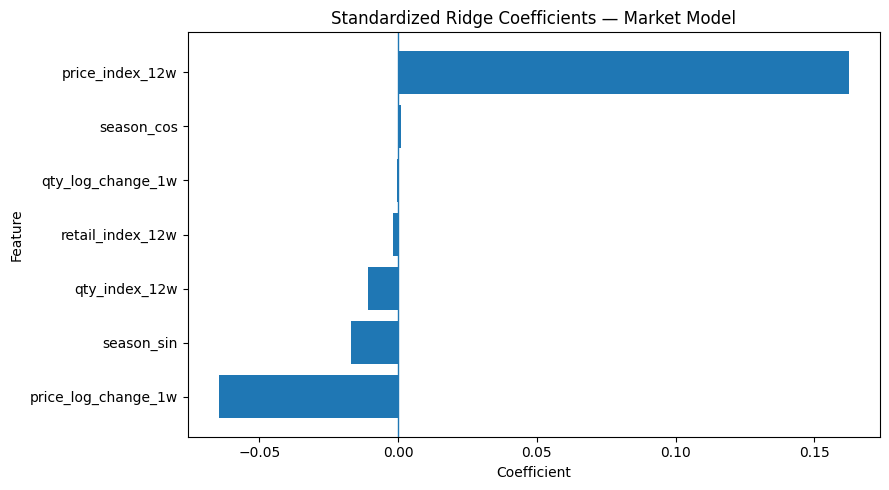

In [35]:
plot_df = (
    market_coef
    .sort_values("coefficient")
)

plt.figure(
    figsize=(9, 5)
)

plt.barh(
    plot_df["feature"],
    plot_df["coefficient"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.title(
    "Standardized Ridge Coefficients — Market Model"
)

plt.xlabel(
    "Coefficient"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plt.show()

In [36]:
ablation_results = []

feature_sets = {
    "Full Market": market_features
}

for feature in market_features:

    feature_sets[
        f"Without {feature}"
    ] = [
        f for f in market_features
        if f != feature
    ]

In [37]:
for model_name, features in feature_sets.items():

    fold_maes = []

    for train_idx, valid_idx in tscv.split(model_df):

        train = model_df.iloc[train_idx]
        valid = model_df.iloc[valid_idx]

        model = make_ridge_model(
            alpha=1.0
        )

        model.fit(
            train[features],
            train["next_price_index"]
        )

        pred = model.predict(
            valid[features]
        )

        fold_maes.append(
            mean_absolute_error(
                valid["next_price_index"],
                pred
            )
        )


    ablation_results.append({
        "model": model_name,
        "mean_mae": np.mean(fold_maes),
        "std_mae": np.std(fold_maes)
    })

In [38]:
ablation_df = (
    pd.DataFrame(ablation_results)
    .sort_values("mean_mae")
    .reset_index(drop=True)
)

ablation_df

,model,mean_mae,std_mae
0,Without season_cos,0.079398,0.010665
1,Without qty_log_change_1w,0.080581,0.009161
2,Without retail_index_12w,0.080942,0.010069
3,Full Market,0.080956,0.010006
4,Without qty_index_12w,0.081143,0.010037
5,Without season_sin,0.084466,0.009165
6,Without price_log_change_1w,0.095388,0.015534
7,Without price_index_12w,0.136153,0.020538


In [39]:
feature_sets_compare = {

    # 기존 전체 Market 모델
    "Full Market": [
        "price_index_12w",
        "qty_index_12w",
        "retail_index_12w",
        "price_log_change_1w",
        "qty_log_change_1w",
        "season_sin",
        "season_cos",
    ],

    # 가격 정보만
    "Price Only": [
        "price_index_12w",
        "price_log_change_1w",
    ],

    # 가격 + 거래활동
    "Price + Qty": [
        "price_index_12w",
        "price_log_change_1w",
        "qty_index_12w",
    ],

    # 가격 + 계절성
    "Price + Season": [
        "price_index_12w",
        "price_log_change_1w",
        "season_sin",
        "season_cos",
    ],

    # 핵심 후보
    "Price + Qty + Season": [
        "price_index_12w",
        "price_log_change_1w",
        "qty_index_12w",
        "season_sin",
        "season_cos",
    ],
}

In [40]:
reduced_results = []


for model_name, features in feature_sets_compare.items():

    for fold, (train_idx, valid_idx) in enumerate(
        tscv.split(model_df),
        start=1
    ):

        train = model_df.iloc[train_idx]
        valid = model_df.iloc[valid_idx]

        model = make_ridge_model(
            alpha=1.0
        )

        model.fit(
            train[features],
            train["next_price_index"]
        )

        pred = model.predict(
            valid[features]
        )

        mae = mean_absolute_error(
            valid["next_price_index"],
            pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                valid["next_price_index"],
                pred
            )
        )

        reduced_results.append({
            "model": model_name,
            "fold": fold,
            "mae": mae,
            "rmse": rmse,
        })

In [41]:
reduced_results_df = pd.DataFrame(
    reduced_results
)

reduced_summary = (
    reduced_results_df
    .groupby("model")
    .agg(
        mean_mae=("mae", "mean"),
        std_mae=("mae", "std"),
        mean_rmse=("rmse", "mean"),
        std_rmse=("rmse", "std"),
    )
    .sort_values("mean_mae")
)

reduced_summary

,mean_mae,std_mae,mean_rmse,std_rmse
model,,,,
Price + Season,0.080258,0.009818,0.093511,0.010324
Price + Qty + Season,0.080604,0.010628,0.094200,0.012087
Full Market,0.080956,0.011554,0.094428,0.012614
Price + Qty,0.082063,0.011856,0.092005,0.010309
Price Only,0.082687,0.011499,0.093589,0.010806


In [42]:
reduced_fold_mae = (
    reduced_results_df
    .pivot(
        index="fold",
        columns="model",
        values="mae"
    )
)

reduced_fold_mae

model,Full Market,Price + Qty,Price + Qty + Season,Price + Season,Price Only
fold,,,,,
1,0.087761,0.089139,0.087595,0.083714,0.086007
2,0.064782,0.065204,0.065552,0.065871,0.065741
3,0.090577,0.091401,0.088568,0.088014,0.091184
4,0.080704,0.082509,0.080700,0.083433,0.087816


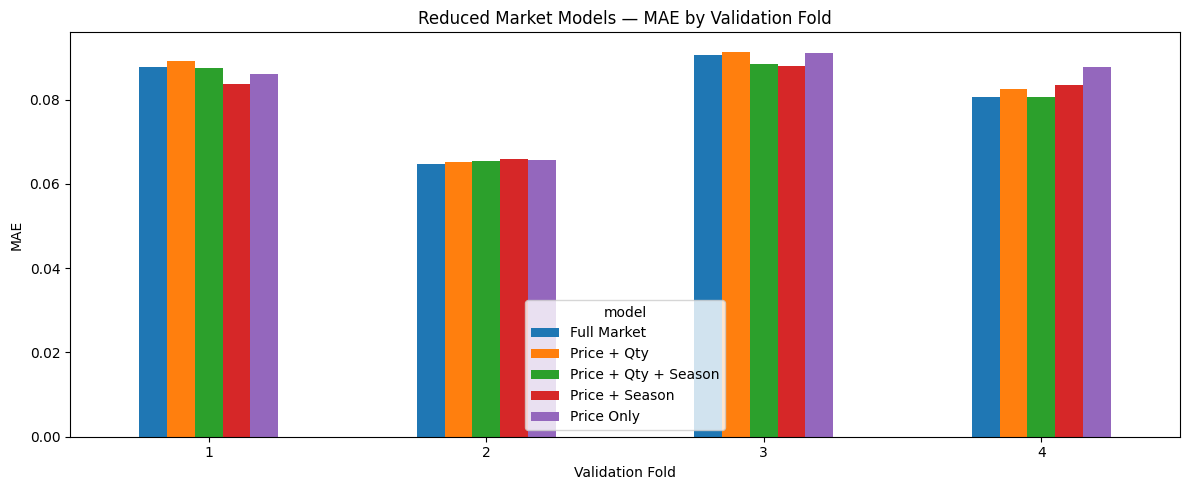

In [43]:
reduced_fold_mae.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title(
    "Reduced Market Models — MAE by Validation Fold"
)

plt.xlabel(
    "Validation Fold"
)

plt.ylabel(
    "MAE"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()

In [44]:
target_summary = (
    model_df["next_price_index"]
    .describe(
        percentiles=[
            0.50,
            0.60,
            0.70,
            0.75,
            0.80,
            0.85,
            0.90,
            0.95,
        ]
    )
)

target_summary

count    115.000000
mean       1.000567
std        0.193374
min        0.469770
50%        1.001832
60%        1.034542
70%        1.077199
75%        1.089364
80%        1.138205
85%        1.181543
90%        1.211917
95%        1.288560
max        1.758463
Name: next_price_index, dtype: float64

In [45]:
threshold_candidates = [
    1.05,
    1.10,
    1.15,
    1.20,
    1.25,
    1.30,
]

threshold_check = []

for threshold in threshold_candidates:

    event_count = (
        model_df["next_price_index"]
        >= threshold
    ).sum()

    event_rate = (
        event_count
        / len(model_df)
    )

    threshold_check.append({
        "threshold": threshold,
        "event_count": event_count,
        "event_rate": event_rate,
    })


threshold_check = pd.DataFrame(
    threshold_check
)

threshold_check["event_rate_pct"] = (
    threshold_check["event_rate"]
    * 100
)

threshold_check

,threshold,event_count,event_rate,event_rate_pct
0,1.05,41,0.356522,35.652174
1,1.10,26,0.226087,22.608696
2,1.15,22,0.191304,19.130435
3,1.20,13,0.113043,11.304348
4,1.25,9,0.078261,7.826087
5,1.30,5,0.043478,4.347826


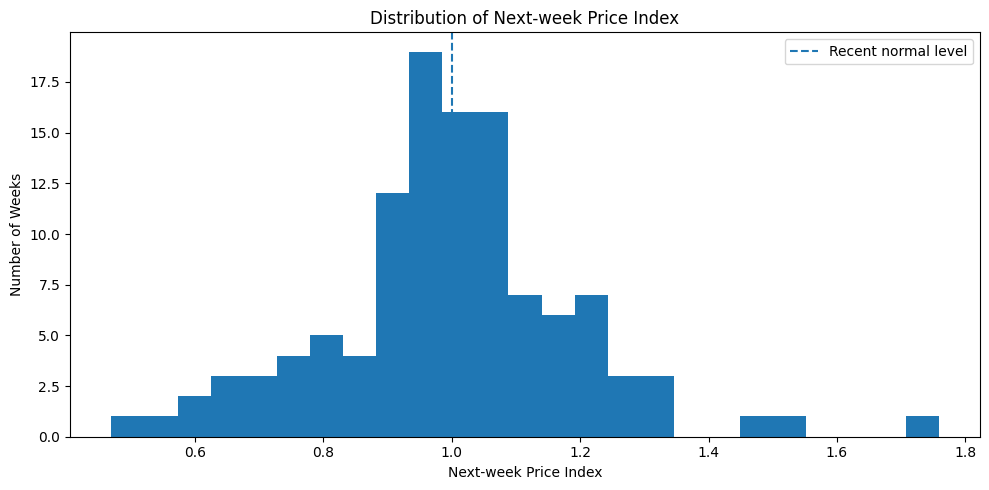

In [46]:
plt.figure(
    figsize=(10, 5)
)

plt.hist(
    model_df["next_price_index"],
    bins=25
)

plt.axvline(
    1.0,
    linestyle="--",
    label="Recent normal level"
)

plt.title(
    "Distribution of Next-week Price Index"
)

plt.xlabel(
    "Next-week Price Index"
)

plt.ylabel(
    "Number of Weeks"
)

plt.legend()

plt.tight_layout()

plt.show()

In [47]:
model_df["next_price_risk_pct"] = (
    model_df["next_price_index"]
    - 1
) * 100

In [48]:
model_df[
    "next_price_risk_pct"
].describe(
    percentiles=[
        0.50,
        0.75,
        0.80,
        0.85,
        0.90,
        0.95,
    ]
)

count    115.000000
mean       0.056743
std       19.337406
min      -53.023035
50%        0.183150
75%        8.936408
80%       13.820509
85%       18.154260
90%       21.191748
95%       28.856021
max       75.846295
Name: next_price_risk_pct, dtype: float64

In [49]:
RISK_THRESHOLD = 1.15

model_df["price_risk_event"] = (
    model_df["next_price_index"]
    >= RISK_THRESHOLD
).astype(int)

model_df[
    "price_risk_event"
].value_counts()

price_risk_event
0    93
1    22
Name: count, dtype: int64

In [50]:
event_summary = (
    model_df["price_risk_event"]
    .value_counts()
    .rename(index={
        0: "Normal",
        1: "Risk"
    })
    .to_frame("count")
)

event_summary["rate_pct"] = (
    event_summary["count"]
    / len(model_df)
    * 100
)

event_summary

,count,rate_pct
price_risk_event,,
Normal,93,80.869565
Risk,22,19.130435


In [51]:
event_fold_check = []

for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(model_df),
    start=1
):

    train = model_df.iloc[train_idx]
    valid = model_df.iloc[valid_idx]

    event_fold_check.append({
        "fold": fold,

        "train_rows": len(train),
        "train_events":
            train["price_risk_event"].sum(),

        "train_event_rate_pct":
            train["price_risk_event"].mean() * 100,

        "valid_rows": len(valid),
        "valid_events":
            valid["price_risk_event"].sum(),

        "valid_event_rate_pct":
            valid["price_risk_event"].mean() * 100,
    })


event_fold_check = pd.DataFrame(
    event_fold_check
)

event_fold_check

,fold,train_rows,train_events,train_event_rate_pct,valid_rows,valid_events,valid_event_rate_pct
0,1,63,12,19.047619,13,1,7.692308
1,2,76,13,17.105263,13,0,0.000000
2,3,89,13,14.606742,13,0,0.000000
3,4,102,13,12.745098,13,9,69.230769


In [52]:
risk_event_features = [
    "price_index_12w",
    "price_log_change_1w",
    "season_sin",
    "season_cos",
]

In [53]:
risk_event_features_qty = [
    "price_index_12w",
    "price_log_change_1w",
    "qty_index_12w",
    "season_sin",
    "season_cos",
]

In [54]:
thresholds = [
    1.05,
    1.10,
    1.15,
    1.20,
]

threshold_fold_results = []


for threshold in thresholds:

    temp = model_df.copy()

    temp["risk_event_temp"] = (
        temp["next_price_index"]
        >= threshold
    ).astype(int)


    for fold, (train_idx, valid_idx) in enumerate(
        tscv.split(temp),
        start=1
    ):

        train = temp.iloc[train_idx]
        valid = temp.iloc[valid_idx]

        threshold_fold_results.append({
            "threshold": threshold,
            "fold": fold,

            "train_events":
                int(train["risk_event_temp"].sum()),

            "train_event_rate_pct":
                train["risk_event_temp"].mean() * 100,

            "valid_events":
                int(valid["risk_event_temp"].sum()),

            "valid_event_rate_pct":
                valid["risk_event_temp"].mean() * 100,
        })


threshold_fold_df = pd.DataFrame(
    threshold_fold_results
)

threshold_fold_df

,threshold,fold,train_events,train_event_rate_pct,valid_events,valid_event_rate_pct
0,1.05,1,22,34.920635,6,46.153846
1,1.05,2,28,36.842105,1,7.692308
2,1.05,3,29,32.584270,2,15.384615
3,1.05,4,31,30.392157,10,76.923077
4,1.10,1,15,23.809524,1,7.692308
5,1.10,2,16,21.052632,0,0.000000
6,1.10,3,16,17.977528,0,0.000000
7,1.10,4,16,15.686275,10,76.923077
8,1.15,1,12,19.047619,1,7.692308
9,1.15,2,13,17.105263,0,0.000000


In [55]:
threshold_event_pivot = (
    threshold_fold_df
    .pivot(
        index="threshold",
        columns="fold",
        values="valid_events"
    )
)

threshold_event_pivot.columns = [
    f"Fold_{col}"
    for col in threshold_event_pivot.columns
]

threshold_event_pivot["total_valid_events"] = (
    threshold_event_pivot.sum(axis=1)
)

threshold_event_pivot

,Fold_1,Fold_2,Fold_3,Fold_4,total_valid_events
threshold,,,,,
1.05,6,1,2,10,19
1.10,1,0,0,10,11
1.15,1,0,0,9,10
1.20,0,0,0,5,5


In [56]:
risk_event_weeks = (
    model_df.loc[
        model_df["next_price_index"] >= 1.15,
        [
            "week_end_date",
            "next_price_index",
            "price_index_12w",
            "price_log_change_1w",
            "qty_index_12w"
        ]
    ]
    .sort_values("week_end_date")
    .reset_index(drop=True)
)

risk_event_weeks

,week_end_date,next_price_index,price_index_12w,price_log_change_1w,qty_index_12w
0,2024-03-03,1.478957,1.019867,0.017842,1.629500
1,2024-03-10,1.507239,1.478957,0.372580,4.530483
2,2024-03-17,1.758463,1.507239,0.018942,2.884509
3,2024-03-24,1.271009,1.758463,0.154161,4.504607
4,2024-03-31,1.285638,1.271009,-0.314754,1.873159
5,2024-04-07,1.197269,1.285638,0.072503,0.803214
6,2024-04-14,1.193198,1.197269,0.045042,0.386128
7,2024-04-21,1.188725,1.193198,0.096000,1.246814
8,2025-07-27,1.307447,1.033054,0.003414,2.670393
9,2025-08-03,1.295379,1.307447,0.235557,2.697347


In [57]:
final_features = [
    "price_index_12w",
    "price_log_change_1w",
    "season_sin",
    "season_cos",
]

In [58]:
risk_predictions = []


for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(model_df),
    start=1
):

    train = model_df.iloc[train_idx]
    valid = model_df.iloc[valid_idx]

    model = make_ridge_model(
        alpha=1.0
    )

    model.fit(
        train[final_features],
        train["next_price_index"]
    )

    pred = model.predict(
        valid[final_features]
    )


    for i in range(len(valid)):

        risk_predictions.append({

            "fold": fold,

            # 현재 판단 시점
            "week_end_date":
                valid.iloc[i]["week_end_date"],

            # 실제 위험이 발생하는 다음 주
            "target_week":
                valid.iloc[i]["week_end_date"]
                + pd.Timedelta(days=7),

            "actual_price_index":
                valid.iloc[i]["next_price_index"],

            "predicted_price_index":
                pred[i],

            "current_price_index":
                valid.iloc[i]["price_index_12w"],

            "qty_index_12w":
                valid.iloc[i]["qty_index_12w"],
        })

In [59]:
risk_pred_df = (
    pd.DataFrame(risk_predictions)
    .sort_values("target_week")
    .reset_index(drop=True)
)

risk_pred_df.head()

,fold,week_end_date,target_week,actual_price_index,predicted_price_index,current_price_index,qty_index_12w
0,1,2025-09-28,2025-10-05,1.017088,0.996978,0.920740,0.945166
1,1,2025-10-05,2025-10-12,1.068100,1.007590,1.017088,2.192146
2,1,2025-10-19,2025-10-26,1.095280,1.097253,1.100832,2.242790
3,1,2025-10-26,2025-11-02,0.956726,1.102037,1.095280,0.747412
4,1,2025-11-02,2025-11-09,1.156110,1.057085,0.956726,1.301470


In [60]:
print("Validation rows:", len(risk_pred_df))

print(
    risk_pred_df["target_week"].min(),
    "~",
    risk_pred_df["target_week"].max()
)

Validation rows: 52
2025-10-05 00:00:00 ~ 2026-10-11 00:00:00


In [61]:
def classify_risk_level(price_index):

    if pd.isna(price_index):
        return np.nan

    if price_index >= 1.15:
        return "Risk"

    elif price_index >= 1.05:
        return "Watch"

    else:
        return "Normal"

In [62]:
risk_pred_df["actual_risk_level"] = (
    risk_pred_df["actual_price_index"]
    .apply(classify_risk_level)
)

risk_pred_df["predicted_risk_level"] = (
    risk_pred_df["predicted_price_index"]
    .apply(classify_risk_level)
)

risk_pred_df[
    [
        "target_week",
        "actual_price_index",
        "predicted_price_index",
        "actual_risk_level",
        "predicted_risk_level"
    ]
].head(20)

,target_week,actual_price_index,predicted_price_index,actual_risk_level,predicted_risk_level
0,2025-10-05,1.017088,0.996978,Normal,Normal
1,2025-10-12,1.068100,1.007590,Watch,Normal
2,2025-10-26,1.095280,1.097253,Watch,Watch
3,2025-11-02,0.956726,1.102037,Normal,Watch
4,2025-11-09,1.156110,1.057085,Risk,Watch
5,2025-11-16,0.953050,1.104553,Normal,Watch
6,2025-11-23,1.092222,1.069739,Watch,Watch
7,2025-11-30,0.929190,1.080004,Normal,Watch
8,2025-12-07,1.096455,1.039348,Watch,Normal
9,2025-12-14,0.946597,1.073215,Normal,Watch


In [63]:
risk_level_summary = pd.DataFrame({

    "actual": (
        risk_pred_df["actual_risk_level"]
        .value_counts()
    ),

    "predicted": (
        risk_pred_df["predicted_risk_level"]
        .value_counts()
    )
}).fillna(0)

risk_level_summary

,actual,predicted
Normal,33,33
Risk,10,6
Watch,9,13


In [64]:
risk_pred_df["actual_risk_event"] = (
    risk_pred_df["actual_price_index"]
    >= 1.15
).astype(int)

In [65]:
risk_pred_df["strict_alert"] = (
    risk_pred_df["predicted_price_index"]
    >= 1.15
).astype(int)

In [66]:
risk_pred_df["early_warning_alert"] = (
    risk_pred_df["predicted_price_index"]
    >= 1.05
).astype(int)

In [67]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


def evaluate_alert(y_true, y_pred):

    return {
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "alerts": int(y_pred.sum()),

        "actual_events": int(y_true.sum()),
    }

In [68]:
strict_result = evaluate_alert(
    risk_pred_df["actual_risk_event"],
    risk_pred_df["strict_alert"]
)

early_result = evaluate_alert(
    risk_pred_df["actual_risk_event"],
    risk_pred_df["early_warning_alert"]
)


alert_summary = pd.DataFrame(
    [
        {
            "policy": "Strict Risk Alert",
            "threshold": 1.15,
            **strict_result
        },

        {
            "policy": "Early Warning",
            "threshold": 1.05,
            **early_result
        }
    ]
)

alert_summary

,policy,threshold,precision,recall,f1,alerts,actual_events
0,Strict Risk Alert,1.15,0.833333,0.5,0.62500,6,10
1,Early Warning,1.05,0.473684,0.9,0.62069,19,10


In [69]:
risk_case_review = (
    risk_pred_df[
        risk_pred_df["actual_risk_event"] == 1
    ][
        [
            "fold",
            "target_week",
            "current_price_index",
            "actual_price_index",
            "predicted_price_index",
            "predicted_risk_level",
            "qty_index_12w",
        ]
    ]
    .reset_index(drop=True)
)

risk_case_review

,fold,target_week,current_price_index,actual_price_index,predicted_price_index,predicted_risk_level,qty_index_12w
0,1,2025-11-09,0.956726,1.156110,1.057085,Watch,1.301470
1,4,2026-07-26,0.982580,1.158288,1.017352,Normal,0.991211
2,4,2026-08-02,1.158288,1.199615,1.056146,Watch,1.464036
3,4,2026-08-09,1.199615,1.275371,1.136892,Watch,0.440604
4,4,2026-08-16,1.275371,1.205943,1.187611,Risk,0.696562
5,4,2026-08-23,1.205943,1.311697,1.178596,Risk,0.738946
6,4,2026-08-30,1.311697,1.231519,1.199605,Risk,0.640652
7,4,2026-09-06,1.231519,1.182188,1.195390,Risk,0.926391
8,4,2026-09-13,1.182188,1.231528,1.152421,Risk,0.926918
9,4,2026-09-27,1.040231,1.175733,1.101819,Watch,1.001729


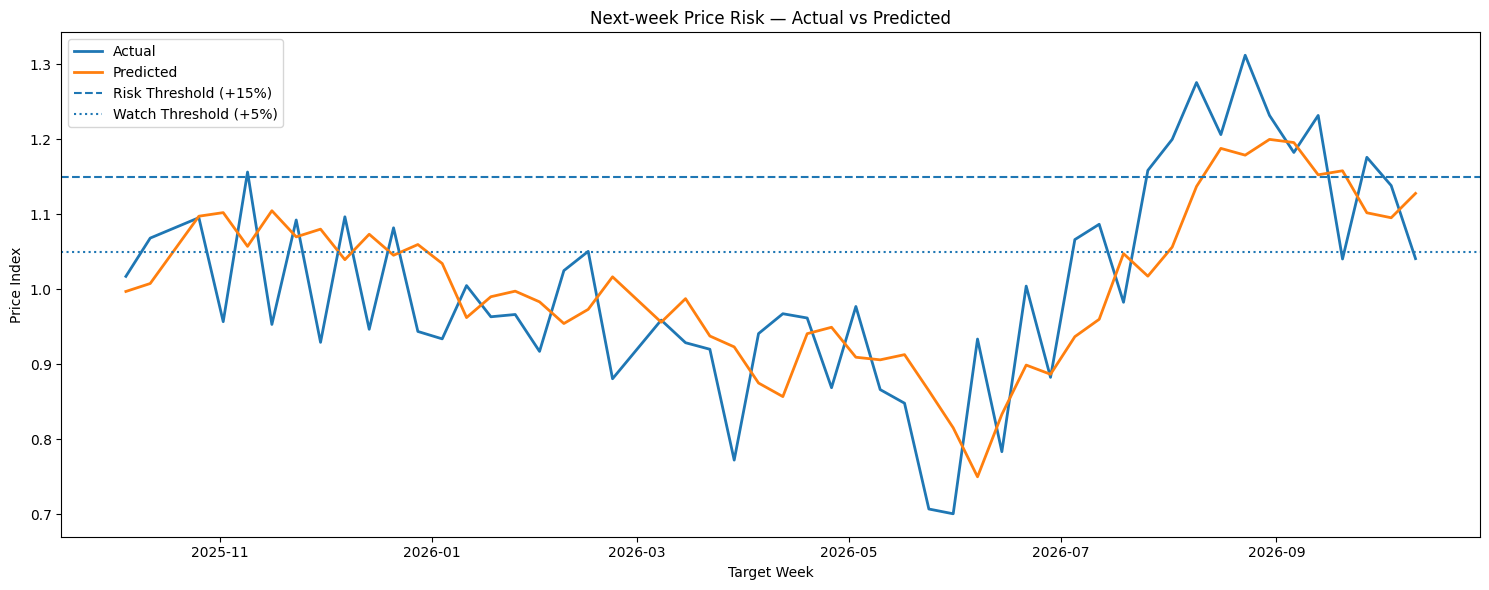

In [70]:
plt.figure(
    figsize=(15, 6)
)

plt.plot(
    risk_pred_df["target_week"],
    risk_pred_df["actual_price_index"],
    label="Actual",
    linewidth=2
)

plt.plot(
    risk_pred_df["target_week"],
    risk_pred_df["predicted_price_index"],
    label="Predicted",
    linewidth=2
)

plt.axhline(
    1.15,
    linestyle="--",
    label="Risk Threshold (+15%)"
)

plt.axhline(
    1.05,
    linestyle=":",
    label="Watch Threshold (+5%)"
)

plt.title(
    "Next-week Price Risk — Actual vs Predicted"
)

plt.xlabel("Target Week")
plt.ylabel("Price Index")

plt.legend()

plt.tight_layout()
plt.show()

In [71]:
RISK_THRESHOLD = 1.15

risk_pred_df["current_risk_event"] = (
    risk_pred_df["current_price_index"]
    >= RISK_THRESHOLD
).astype(int)

risk_pred_df["next_risk_event"] = (
    risk_pred_df["actual_price_index"]
    >= RISK_THRESHOLD
).astype(int)

In [72]:
def classify_risk_transition(row):

    current = row["current_risk_event"]
    next_ = row["next_risk_event"]

    if current == 0 and next_ == 1:
        return "Onset"

    elif current == 1 and next_ == 1:
        return "Persistence"

    elif current == 1 and next_ == 0:
        return "Exit"

    else:
        return "Normal"


risk_pred_df["risk_transition"] = (
    risk_pred_df.apply(
        classify_risk_transition,
        axis=1
    )
)

In [73]:
transition_summary = (
    risk_pred_df["risk_transition"]
    .value_counts()
    .to_frame("count")
)

transition_summary["rate_pct"] = (
    transition_summary["count"]
    / len(risk_pred_df)
    * 100
)

transition_summary

,count,rate_pct
risk_transition,,
Normal,39,75.000000
Persistence,7,13.461538
Onset,3,5.769231
Exit,3,5.769231


In [74]:
onset_cases = (
    risk_pred_df[
        risk_pred_df["risk_transition"] == "Onset"
    ][
        [
            "fold",
            "target_week",
            "current_price_index",
            "actual_price_index",
            "predicted_price_index",
            "predicted_risk_level",
            "qty_index_12w",
        ]
    ]
    .reset_index(drop=True)
)

onset_cases

,fold,target_week,current_price_index,actual_price_index,predicted_price_index,predicted_risk_level,qty_index_12w
0,1,2025-11-09,0.956726,1.156110,1.057085,Watch,1.301470
1,4,2026-07-26,0.982580,1.158288,1.017352,Normal,0.991211
2,4,2026-09-27,1.040231,1.175733,1.101819,Watch,1.001729


In [75]:
WATCH_THRESHOLD = 1.05

risk_pred_df["forecast_warning"] = (
    risk_pred_df["predicted_price_index"]
    >= WATCH_THRESHOLD
).astype(int)

In [76]:
onset_df = risk_pred_df[
    risk_pred_df["risk_transition"] == "Onset"
].copy()

onset_recall = (
    onset_df["forecast_warning"].mean()
)

print(
    "Risk Onset Events:",
    len(onset_df)
)

print(
    "Detected Onsets:",
    int(onset_df["forecast_warning"].sum())
)

print(
    f"Onset Recall: {onset_recall:.3f}"
)

Risk Onset Events: 3
Detected Onsets: 2
Onset Recall: 0.667


In [77]:
persistence_df = risk_pred_df[
    risk_pred_df["risk_transition"] == "Persistence"
].copy()

persistence_recall = (
    persistence_df["forecast_warning"]
    .mean()
)

print(
    "Risk Persistence Events:",
    len(persistence_df)
)

print(
    "Detected Persistence:",
    int(
        persistence_df[
            "forecast_warning"
        ].sum()
    )
)

print(
    f"Persistence Recall: "
    f"{persistence_recall:.3f}"
)

Risk Persistence Events: 7
Detected Persistence: 7
Persistence Recall: 1.000


In [78]:
risk_pred_df["current_risk_level"] = (
    risk_pred_df["current_price_index"]
    .apply(classify_risk_level)
)

risk_pred_df["forecast_risk_level"] = (
    risk_pred_df["predicted_price_index"]
    .apply(classify_risk_level)
)

In [79]:
def classify_risk_level(price_index):

    if pd.isna(price_index):
        return np.nan

    if price_index >= 1.15:
        return "Risk"

    elif price_index >= 1.05:
        return "Watch"

    else:
        return "Normal"

In [80]:
def classify_operational_signal(row):

    current = row["current_risk_level"]
    forecast = row["forecast_risk_level"]

    # 현재 정상
    if current == "Normal":

        if forecast == "Normal":
            return "Stable"

        elif forecast == "Watch":
            return "Early Watch"

        elif forecast == "Risk":
            return "Risk Entry Warning"

    # 현재 Watch
    elif current == "Watch":

        if forecast == "Normal":
            return "Watch Easing"

        elif forecast == "Watch":
            return "Watch Persistence"

        elif forecast == "Risk":
            return "Risk Escalation"

    # 현재 Risk
    elif current == "Risk":

        if forecast == "Normal":
            return "Risk Recovery"

        elif forecast == "Watch":
            return "Risk Easing"

        elif forecast == "Risk":
            return "Ongoing Risk"

    return "Unknown"


risk_pred_df["operational_signal"] = (
    risk_pred_df.apply(
        classify_operational_signal,
        axis=1
    )
)

In [81]:
priority_map = {

    "Stable": 0,

    "Watch Easing": 1,
    "Watch Persistence": 1,

    "Early Watch": 2,
    "Risk Recovery": 2,
    "Risk Easing": 2,

    "Risk Entry Warning": 3,
    "Risk Escalation": 3,
    "Ongoing Risk": 3,
}


risk_pred_df["alert_priority"] = (
    risk_pred_df["operational_signal"]
    .map(priority_map)
)

In [82]:
def classify_qty_context(qty_index):

    if pd.isna(qty_index):
        return "Unknown"

    if qty_index < 0.7:
        return "Low Activity"

    elif qty_index > 1.3:
        return "High Activity"

    else:
        return "Normal Activity"


risk_pred_df["qty_context"] = (
    risk_pred_df["qty_index_12w"]
    .apply(classify_qty_context)
)

In [83]:
decision_view = risk_pred_df[
    [
        "week_end_date",
        "target_week",

        "current_price_index",
        "predicted_price_index",
        "actual_price_index",

        "current_risk_level",
        "forecast_risk_level",

        "operational_signal",
        "alert_priority",

        "qty_index_12w",
        "qty_context",

        "fold",
    ]
].copy()


decision_view = (
    decision_view
    .sort_values(
        ["target_week"]
    )
    .reset_index(drop=True)
)

decision_view.tail(20)

,week_end_date,target_week,current_price_index,predicted_price_index,actual_price_index,current_risk_level,forecast_risk_level,operational_signal,alert_priority,qty_index_12w,qty_context,fold
32,2026-05-24,2026-05-31,0.707131,0.815363,0.700753,Normal,Normal,Stable,0,1.458991,High Activity,3
33,2026-05-31,2026-06-07,0.700753,0.750024,0.933589,Normal,Normal,Stable,0,0.967564,Normal Activity,3
34,2026-06-07,2026-06-14,0.933589,0.833220,0.783493,Normal,Normal,Stable,0,0.685487,Low Activity,3
35,2026-06-14,2026-06-21,0.783493,0.898905,1.004132,Normal,Normal,Stable,0,0.845428,Normal Activity,3
36,2026-06-21,2026-06-28,1.004132,0.886653,0.882548,Normal,Normal,Stable,0,0.943712,Normal Activity,3
37,2026-06-28,2026-07-05,0.882548,0.936762,1.066115,Normal,Normal,Stable,0,0.379794,Low Activity,3
38,2026-07-05,2026-07-12,1.066115,0.959914,1.086507,Watch,Normal,Watch Easing,1,1.555587,High Activity,3
39,2026-07-12,2026-07-19,1.086507,1.047383,0.982580,Watch,Normal,Watch Easing,1,1.443089,High Activity,4
40,2026-07-19,2026-07-26,0.982580,1.017352,1.158288,Normal,Normal,Stable,0,0.991211,Normal Activity,4
41,2026-07-26,2026-08-02,1.158288,1.056146,1.199615,Risk,Watch,Risk Easing,2,1.464036,High Activity,4


In [84]:
priority_cases = (
    decision_view[
        decision_view["alert_priority"] >= 2
    ]
    .sort_values(
        "target_week"
    )
    .reset_index(drop=True)
)

priority_cases

,week_end_date,target_week,current_price_index,predicted_price_index,actual_price_index,current_risk_level,forecast_risk_level,operational_signal,alert_priority,qty_index_12w,qty_context,fold
0,2025-11-02,2025-11-09,0.956726,1.057085,1.156110,Normal,Watch,Early Watch,2,1.301470,High Activity,1
1,2025-11-09,2025-11-16,1.156110,1.104553,0.953050,Risk,Watch,Risk Easing,2,1.225543,Normal Activity,1
2,2025-11-16,2025-11-23,0.953050,1.069739,1.092222,Normal,Watch,Early Watch,2,0.531572,Low Activity,1
3,2026-07-26,2026-08-02,1.158288,1.056146,1.199615,Risk,Watch,Risk Easing,2,1.464036,High Activity,4
4,2026-08-02,2026-08-09,1.199615,1.136892,1.275371,Risk,Watch,Risk Easing,2,0.440604,Low Activity,4
5,2026-08-09,2026-08-16,1.275371,1.187611,1.205943,Risk,Risk,Ongoing Risk,3,0.696562,Low Activity,4
6,2026-08-16,2026-08-23,1.205943,1.178596,1.311697,Risk,Risk,Ongoing Risk,3,0.738946,Normal Activity,4
7,2026-08-23,2026-08-30,1.311697,1.199605,1.231519,Risk,Risk,Ongoing Risk,3,0.640652,Low Activity,4
8,2026-08-30,2026-09-06,1.231519,1.195390,1.182188,Risk,Risk,Ongoing Risk,3,0.926391,Normal Activity,4
9,2026-09-06,2026-09-13,1.182188,1.152421,1.231528,Risk,Risk,Ongoing Risk,3,0.926918,Normal Activity,4


In [85]:
high_priority_cases = (
    decision_view[
        decision_view["alert_priority"] == 3
    ]
    .reset_index(drop=True)
)

high_priority_cases

,week_end_date,target_week,current_price_index,predicted_price_index,actual_price_index,current_risk_level,forecast_risk_level,operational_signal,alert_priority,qty_index_12w,qty_context,fold
0,2026-08-09,2026-08-16,1.275371,1.187611,1.205943,Risk,Risk,Ongoing Risk,3,0.696562,Low Activity,4
1,2026-08-16,2026-08-23,1.205943,1.178596,1.311697,Risk,Risk,Ongoing Risk,3,0.738946,Normal Activity,4
2,2026-08-23,2026-08-30,1.311697,1.199605,1.231519,Risk,Risk,Ongoing Risk,3,0.640652,Low Activity,4
3,2026-08-30,2026-09-06,1.231519,1.195390,1.182188,Risk,Risk,Ongoing Risk,3,0.926391,Normal Activity,4
4,2026-09-06,2026-09-13,1.182188,1.152421,1.231528,Risk,Risk,Ongoing Risk,3,0.926918,Normal Activity,4
5,2026-09-13,2026-09-20,1.231528,1.157785,1.040231,Risk,Risk,Ongoing Risk,3,1.074616,Normal Activity,4


In [86]:
signal_summary = (
    decision_view["operational_signal"]
    .value_counts()
    .to_frame("count")
)

signal_summary["rate_pct"] = (
    signal_summary["count"]
    / len(decision_view)
    * 100
)

signal_summary

,count,rate_pct
operational_signal,,
Stable,29,55.769231
Watch Persistence,6,11.538462
Ongoing Risk,6,11.538462
Risk Easing,4,7.692308
Watch Easing,4,7.692308
Early Watch,3,5.769231


In [87]:
priority_label_map = {
    0: "Monitor",
    1: "Low",
    2: "Early Warning",
    3: "Active Risk",
}

risk_pred_df["alert_priority_label"] = (
    risk_pred_df["alert_priority"]
    .map(priority_label_map)
)

In [88]:
decision_view = risk_pred_df[
    [
        "week_end_date",
        "target_week",

        "current_price_index",
        "predicted_price_index",
        "actual_price_index",

        "current_risk_level",
        "forecast_risk_level",

        "operational_signal",
        "alert_priority",
        "alert_priority_label",

        "qty_index_12w",
        "qty_context",

        "fold",
    ]
].copy()

In [89]:
validation_kpi = pd.DataFrame([
    {
        "metric": "Naive MAE",
        "value": 0.099708
    },
    {
        "metric": "Final Price + Season MAE",
        "value": 0.081113
    },
    {
        "metric": "MAE Improvement vs Naive (%)",
        "value": (
            (0.099708 - 0.081113)
            / 0.099708
            * 100
        )
    },
    {
        "metric": "Risk Onset Cases",
        "value": 3
    },
    {
        "metric": "Risk Onset Detected",
        "value": 2
    },
    {
        "metric": "Risk Onset Recall",
        "value": 2 / 3
    },
    {
        "metric": "Risk Persistence Cases",
        "value": 7
    },
    {
        "metric": "Risk Persistence Detected",
        "value": 7
    },
    {
        "metric": "Risk Persistence Recall",
        "value": 1.0
    },
])

validation_kpi

,metric,value
0,Naive MAE,0.099708
1,Final Price + Season MAE,0.081113
2,MAE Improvement vs Naive (%),18.649456
3,Risk Onset Cases,3.000000
4,Risk Onset Detected,2.000000
5,Risk Onset Recall,0.666667
6,Risk Persistence Cases,7.000000
7,Risk Persistence Detected,7.000000
8,Risk Persistence Recall,1.000000


In [90]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(
    parents=True,
    exist_ok=True
)

risk_pred_df.to_csv(
    output_dir / "price_risk_oof_predictions.csv",
    index=False
)

print(
    "Saved:",
    output_dir / "price_risk_oof_predictions.csv"
)

Saved: ../data/processed/price_risk_oof_predictions.csv
